In [12]:
!pip install thefittest==0.3.0

ERROR: Ignored the following versions that require a different python version: 0.1.10 Requires-Python <3.11,>=3.7; 0.1.11 Requires-Python <3.11,>=3.7; 0.1.13 Requires-Python <3.11,>=3.7; 0.1.14 Requires-Python <3.11,>=3.7; 0.1.15 Requires-Python <3.11,>=3.7; 0.1.9 Requires-Python <=3.10,>=3.7; 0.2.0 Requires-Python <3.11,>=3.7
ERROR: Could not find a version that satisfies the requirement thefittest==0.3.0 (from versions: 0.1.7, 0.1.8, 0.2.1, 0.2.2, 0.2.3, 0.2.4, 0.2.5, 0.2.6, 0.2.7)
ERROR: No matching distribution found for thefittest==0.3.0

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [13]:
!pip install plotly nbformat matplotlib



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


##OneMax problem

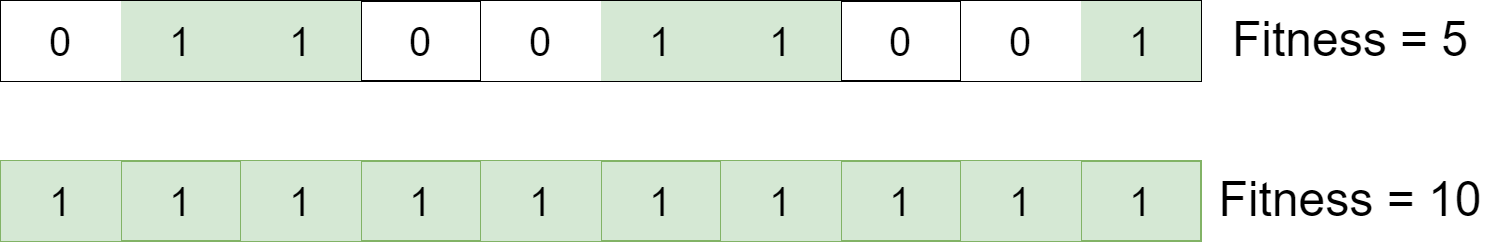

## OneMax problem with 1000 bits

In [14]:
from thefittest.benchmarks import OneMax
from thefittest.optimizers import GeneticAlgorithm

number_of_iterations = 200
population_size = 200
string_length = 1000

optimizer = GeneticAlgorithm(fitness_function=OneMax(),
                         iters=number_of_iterations,
                         pop_size=population_size,
                         str_len=string_length,
                         show_progress_each=10)

optimizer.fit()

fittest = optimizer.get_fittest()
print("fittest", fittest["genotype"])

0-th iteration with the best fitness = 558.0
10-th iteration with the best fitness = 672.0
20-th iteration with the best fitness = 783.0
30-th iteration with the best fitness = 864.0
40-th iteration with the best fitness = 918.0
50-th iteration with the best fitness = 946.0
60-th iteration with the best fitness = 958.0
70-th iteration with the best fitness = 968.0
80-th iteration with the best fitness = 975.0
90-th iteration with the best fitness = 980.0
100-th iteration with the best fitness = 985.0
110-th iteration with the best fitness = 990.0
120-th iteration with the best fitness = 993.0
130-th iteration with the best fitness = 997.0
140-th iteration with the best fitness = 998.0
150-th iteration with the best fitness = 999.0
160-th iteration with the best fitness = 1000.0
170-th iteration with the best fitness = 1000.0
180-th iteration with the best fitness = 1000.0
190-th iteration with the best fitness = 1000.0
fittest [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 

## Rastrign problem with 10 variables

In [15]:
import numpy as np
import plotly.graph_objects as go

from thefittest.benchmarks import Rastrigin

# Generate grid data for the surface plot
x_plot = np.linspace(-5, 5, 500)
y_plot = np.linspace(-5, 5, 500)
z_plot = Rastrigin().build_grid(x_plot, y_plot)

# Create a figure and add a surface to it
fig = go.Figure(data=[go.Surface(x=x_plot, y=y_plot, z=z_plot)])

# Show the figure
fig.show()

In [16]:
from thefittest.optimizers import SelfCGA
from thefittest.utils.transformations import GrayCode


n_dimension = 10
left_border = -5.
right_border = 5.
number_of_generations = 500
population_size = 500

genotype_to_phenotype = GrayCode()
genotype_to_phenotype.fit(left_border=left_border,
                          right_border=right_border,
                          num_variables=n_dimension,
                          h_per_variable=0.001)
num_bits = genotype_to_phenotype.get_bits_per_variable().sum()


optimizer = SelfCGA(fitness_function=Rastrigin(),
                    genotype_to_phenotype=genotype_to_phenotype.transform,
                    iters=number_of_generations,
                    pop_size=population_size,
                    str_len=num_bits,
                    show_progress_each=30,
                    minimization=True,
                    keep_history=True,
                    optimal_value=0.)

optimizer.fit()

fittest = optimizer.get_fittest()

print('The fittest individ:', fittest['genotype'])
print('The fittest individ:', fittest['phenotype'])
print('with fitness', fittest['fitness'])

0-th iteration with the best fitness = 91.59126496665043
30-th iteration with the best fitness = 14.262720016446622
60-th iteration with the best fitness = 8.478006981144592
90-th iteration with the best fitness = 3.6012282983907067
120-th iteration with the best fitness = 1.9911379444861108
150-th iteration with the best fitness = 0.9951409507501019
180-th iteration with the best fitness = 0.9951409507501019
210-th iteration with the best fitness = 0.9951409507501019
240-th iteration with the best fitness = 0.9951409507501019
270-th iteration with the best fitness = 0.9951409507501019
300-th iteration with the best fitness = 0.9951409507501019
330-th iteration with the best fitness = 0.9951409507501019
360-th iteration with the best fitness = 0.9951409507501019
390-th iteration with the best fitness = 0.9951409507501019
420-th iteration with the best fitness = 0.9951409507501019
450-th iteration with the best fitness = 0.9951409507501019
480-th iteration with the best fitness = 0.9951

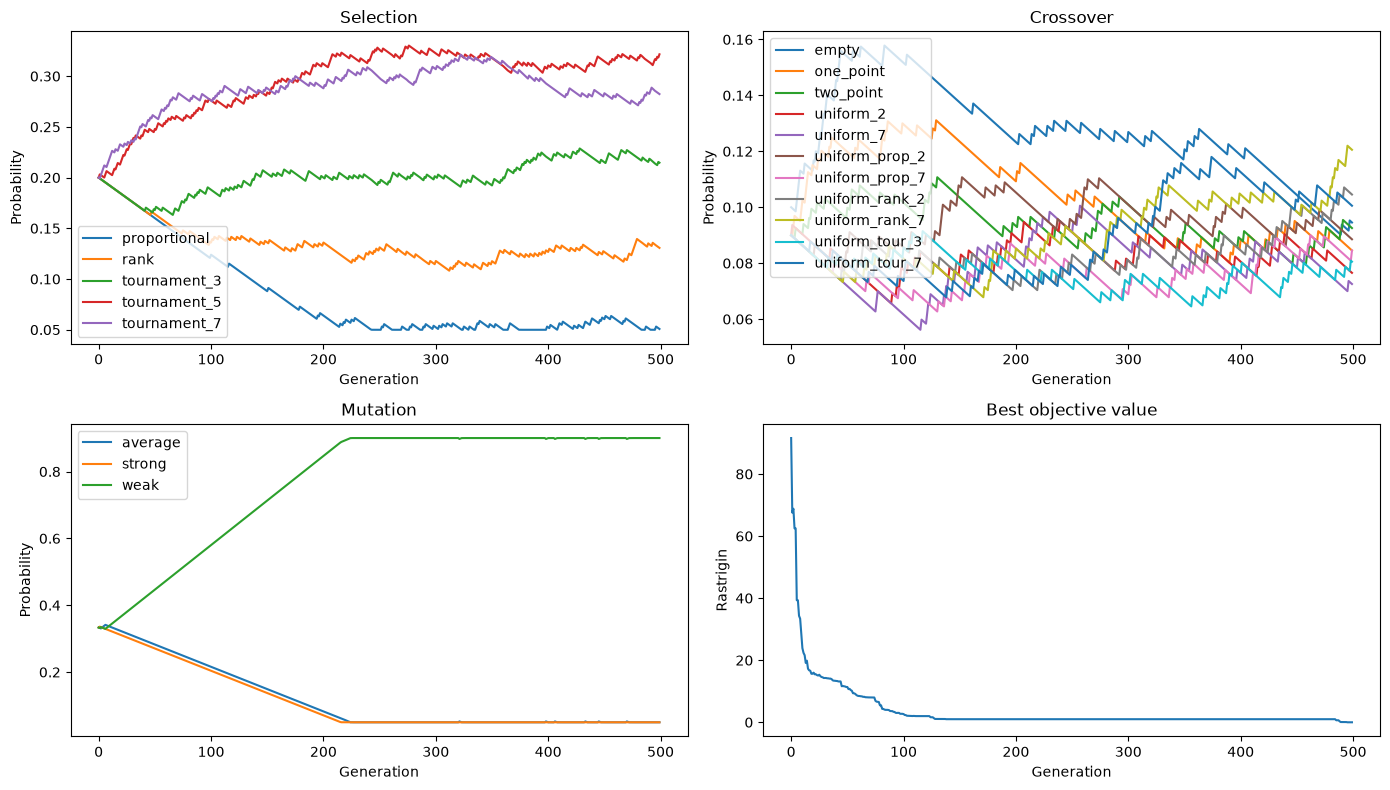

In [17]:
import matplotlib.pyplot as plt

stats = optimizer.get_stats()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, key, title in zip(axes.flat, ["s_proba", "c_proba", "m_proba"],
                          ["Selection", "Crossover", "Mutation"]):
    for operator in stats[key][0]:
        ax.plot([step[operator] for step in stats[key]], label=operator)
    ax.set(title=title, ylabel="Probability")
    ax.legend()
axes[1, 1].plot(-np.array(stats["max_fitness"]))
axes[1, 1].set(title="Best objective value", ylabel="Rastrigin")
for ax in axes.flat:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.show()


## CEC2005 F10 with SelfCSHAGA

Shifted and rotated Rastrigin with 30 variables. The global minimum is −330.

In [22]:
from thefittest.optimizers import SelfCSHAGA
from thefittest.benchmarks.CEC2005 import problems_dict

benchmark = problems_dict["F10"]
problem = benchmark["function"]()
left_border, right_border = benchmark["bounds"]

rotated_encoding = GrayCode()
rotated_encoding.fit(left_border=left_border, right_border=right_border,
                     num_variables=30, h_per_variable=0.001)

shaga_optimizer = SelfCSHAGA(
    fitness_function=problem,
    genotype_to_phenotype=rotated_encoding.transform,
    iters=300,
    pop_size=300,
    str_len=rotated_encoding.get_bits_per_variable().sum(),
    minimization=True,
    keep_history=True,
    show_progress_each=30,
    optimal_value=benchmark["optimum"],
    )
shaga_optimizer.fit()
fittest = shaga_optimizer.get_fittest()
print("Best solution:", fittest["phenotype"])
print("CEC2005 F10:", -fittest["fitness"])
print("Known optimum:", benchmark["optimum"])


0-th iteration with the best fitness = 448.9808572180509
30-th iteration with the best fitness = -72.38168304061026
60-th iteration with the best fitness = -117.49867886632242
90-th iteration with the best fitness = -186.59295920466002
120-th iteration with the best fitness = -247.31267066748632
150-th iteration with the best fitness = -270.62814172568886
180-th iteration with the best fitness = -286.30424680691647
210-th iteration with the best fitness = -289.83339667530373
240-th iteration with the best fitness = -290.60503761881876
270-th iteration with the best fitness = -291.00528406709554
Best solution: [ 1.11609595 -2.03412073 -0.59421351 -2.26057499  1.96880913 -2.52304218
  2.34908136 -3.32997619  1.12891412 -4.37374107  4.017274   -2.37654886
 -0.53927852  2.94970396  1.0208753  -3.48562534  2.22334127  1.88823781
 -2.50900324  4.82664958 -1.76554966  4.43905268 -3.13404138 -2.97839224
 -1.81315998  1.97369224 -0.95312214 -1.49942013  0.19624    -2.24958799]
CEC2005 F10: -291

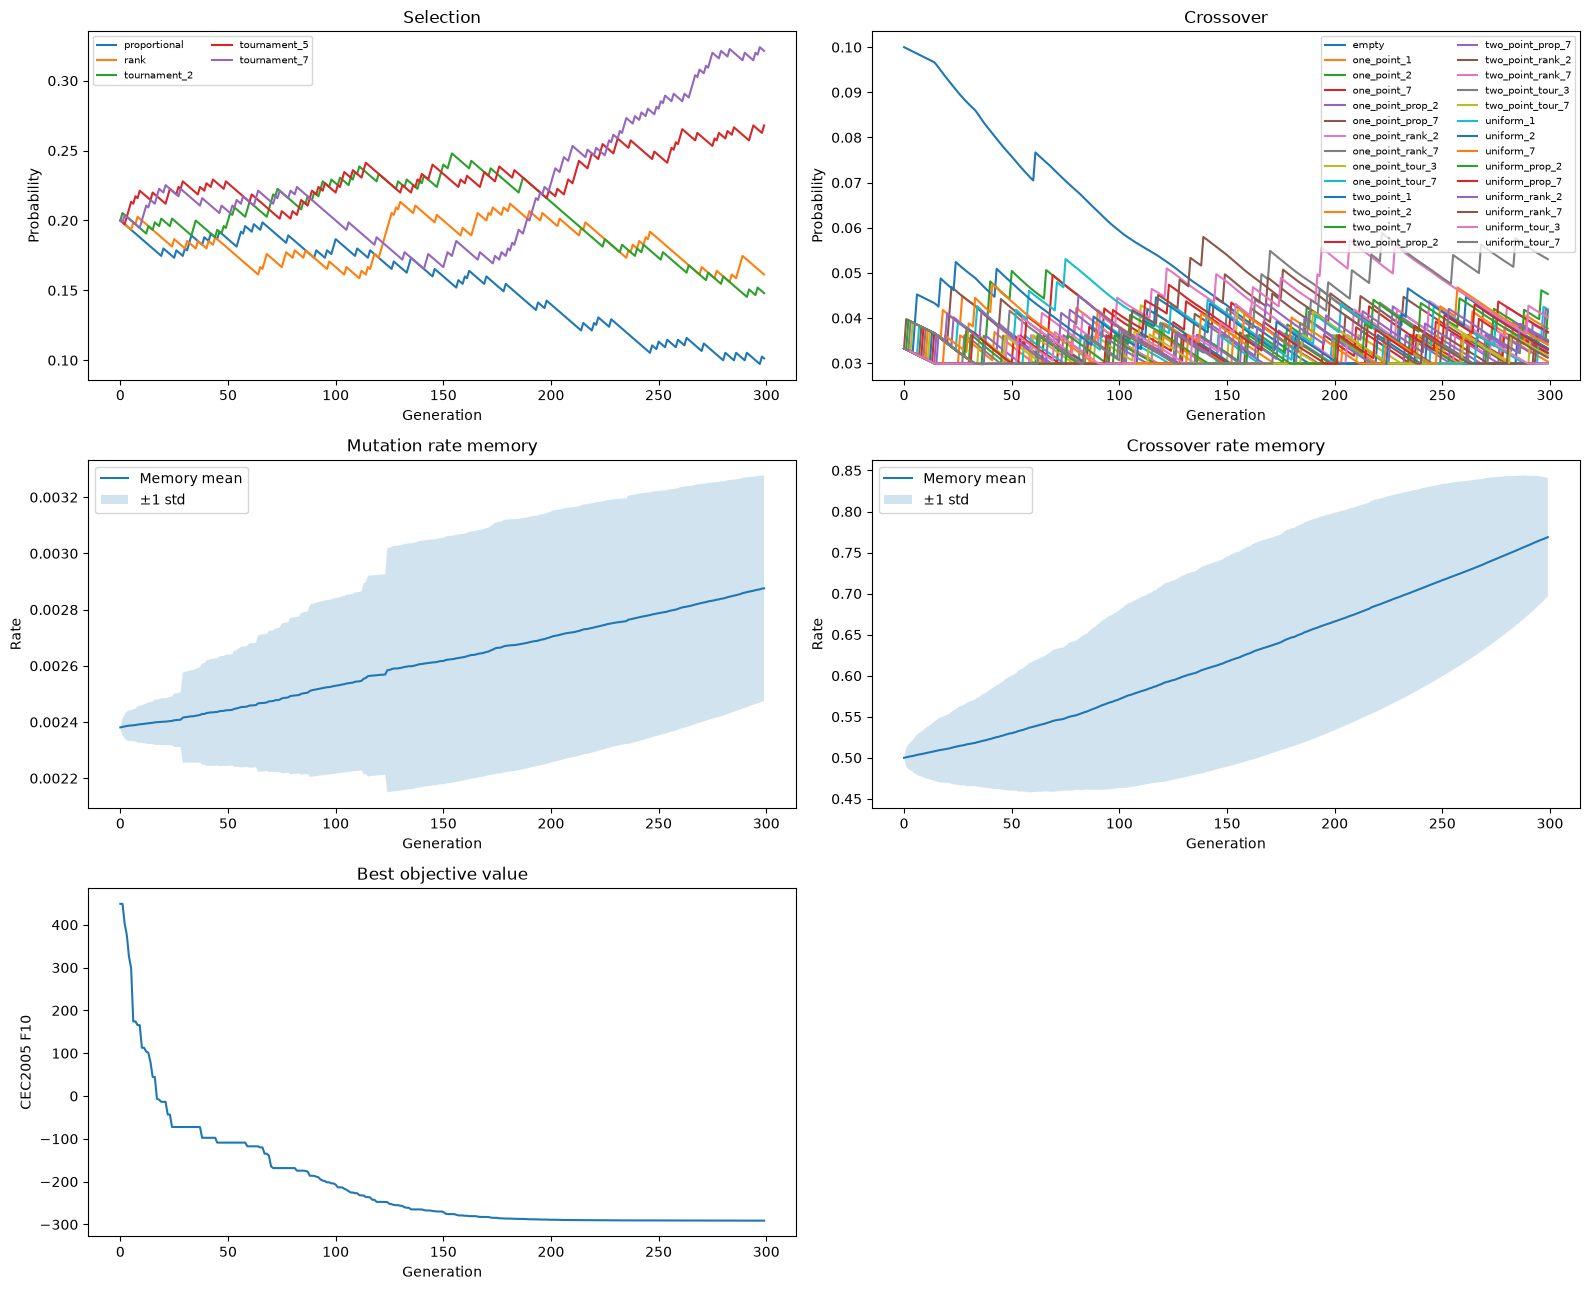

In [23]:
stats = shaga_optimizer.get_stats()
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for ax, key, title in zip(axes[0], ["s_proba", "c_proba"], ["Selection", "Crossover"]):
    for operator in stats[key][0]:
        ax.plot([step[operator] for step in stats[key]], label=operator)
    ax.set(title=title, ylabel="Probability")
    ax.legend(fontsize=7, ncol=2)
for ax, key, title in zip(axes[1], ["H_MR", "H_CR"],
                          ["Mutation rate memory", "Crossover rate memory"]):
    memory = np.array(stats[key])
    generations = np.arange(len(memory))
    mean = memory.mean(axis=1)
    std = memory.std(axis=1)
    ax.plot(generations, mean, label="Memory mean")
    ax.fill_between(generations, mean - std, mean + std,
                    alpha=0.2, label="±1 std")
    ax.set(title=title, ylabel="Rate")
    ax.legend()
axes[2, 0].plot(-np.array(stats["max_fitness"]))
axes[2, 0].set(title="Best objective value", ylabel="CEC2005 F10")
axes[2, 1].axis("off")
for ax in axes.flat[:-1]:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.show()
